# Polynomial Regression from Scratch

This project implements quadratic polynomial regression using manually derived
gradients and NumPy. It explores how gradient descent learns model parameters
and how optimization choices affect convergence and predictive performance.

## Model

The model represents a curved relationship between an input and its target:

$$
\hat{y} = \theta_0 + \theta_1 x + \theta_2 x^2
$$

Although the prediction is nonlinear in the input, it is linear in the
parameters. With mean squared error as the objective, this produces a convex
optimization problem.

## Objectives

- Derive and implement the gradients of mean squared error.
- Train polynomial regression using full-batch and mini-batch gradient descent.
- Examine convergence through loss curves and parameter trajectories.
- Explore the effect of L2 regularization.
- Compare the custom implementation with NumPy, SciPy, and scikit-learn.

## Approach

Experiments use reproducible synthetic data with a known quadratic relationship
and Gaussian noise. The core model and optimization algorithms are implemented
manually; library fitting methods serve as reference solutions.

## Synthetic Data Generation

We generate 100 evenly spaced inputs and normalize them to the interval
[-1, 1] before constructing the target:

$$
z = x / 10,\qquad y = 1 + 2z + 3z^2 + \epsilon
$$

where $\epsilon \sim \mathcal{N}(0, 3^2)$.

The true coefficients in the normalized input space are [1, 2, 3].
Normalization keeps polynomial features small, which helps numerical stability
during gradient descent.

Targets are generated from normalized inputs. This defines a quadratic
experiment on [-1, 1], rather than preserving targets generated on [-10, 10].

A fixed random seed makes the generated observations reproducible.

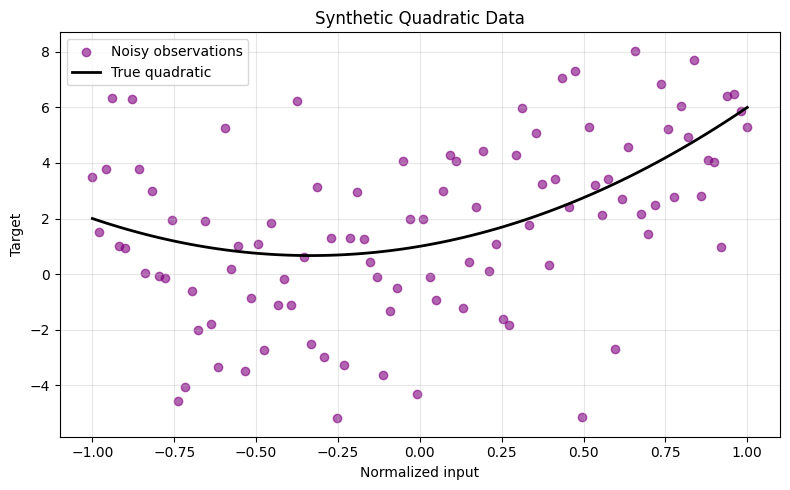

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Preserve reproducibility of the original experiment.
np.random.seed(42)

N_SAMPLES = 100
INPUT_SCALE = 10.0
NOISE_STD = 3.0
TRUE_THETA = np.array([1.0, 2.0, 3.0])

X = np.linspace(-10.0, 10.0, N_SAMPLES)
X_scaled = X / INPUT_SCALE

# Construct the target in the normalized input space.
y_true = (
    TRUE_THETA[0]
    + TRUE_THETA[1] * X_scaled
    + TRUE_THETA[2] * X_scaled**2
)
epsilon = np.random.normal(0.0, NOISE_STD, size=N_SAMPLES)
y = y_true + epsilon

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_scaled, y, color="purple", alpha=0.6, label="Noisy observations")
ax.plot(X_scaled, y_true, color="black", linewidth=2, label="True quadratic")
ax.set(
    title="Synthetic Quadratic Data",
    xlabel="Normalized input",
    ylabel="Target",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Training and Test Split

The observations are ordered by input value. We use the first 80% for
training and the remaining 20% for testing, without shuffling.

- Training inputs span approximately -1.00 to 0.60.
- Test inputs span approximately 0.62 to 1.00.

Because all test inputs lie beyond the training range, this evaluates
extrapolation over the held-out upper portion of the input domain.

Test MSE measures performance on these 20 observations. It does not establish
performance across other datasets, random seeds, or input ranges.

Training samples: 80
Test samples: 20
Training input range: [-1.000, 0.596]
Test input range: [0.616, 1.000]


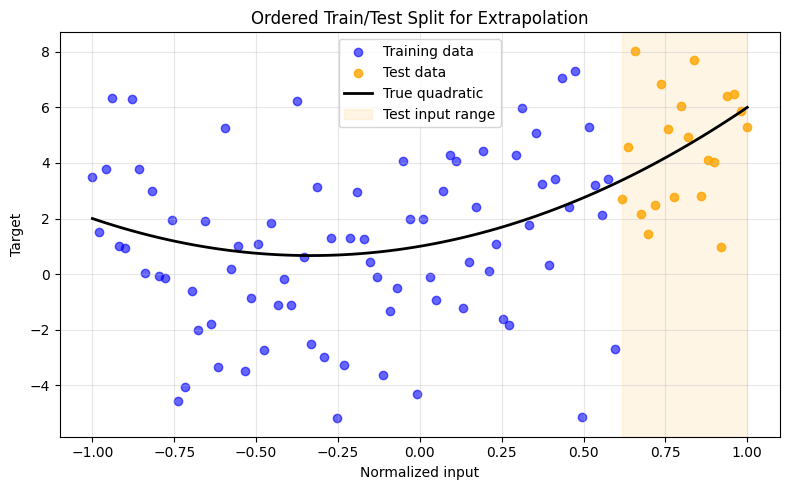

In [2]:
# Preserve input order to evaluate extrapolation.
TRAIN_FRACTION = 0.8
train_size = int(TRAIN_FRACTION * len(X_scaled))

X_train, X_test = X_scaled[:train_size], X_scaled[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Training input range: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Test input range: [{X_test.min():.3f}, {X_test.max():.3f}]")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train, y_train, color="blue", alpha=0.6, label="Training data")
ax.scatter(X_test, y_test, color="orange", alpha=0.8, label="Test data")
ax.plot(X_scaled, y_true, color="black", linewidth=2, label="True quadratic")

# Shade the input interval reserved for testing.
ax.axvspan(
    X_test.min(), X_test.max(),
    color="orange", alpha=0.1, label="Test input range",
)

ax.set(
    title="Ordered Train/Test Split for Extrapolation",
    xlabel="Normalized input",
    ylabel="Target",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Quadratic Model

The model predicts targets using an intercept, a linear term, and a
quadratic term:

$$
\hat{y} = \theta_0 + \theta_1 x + \theta_2 x^2
$$

The design matrix contains one row per observation and columns [1, x, x²].
Multiplying it by the parameter vector produces all predictions at once.
Here, x denotes the normalized input.

In [3]:
def design_matrix(X):
    """Construct quadratic features [1, x, x²] for a 1D input array."""
    return np.column_stack((np.ones_like(X), X, X**2))


def predict(X, theta):
    """Predict targets using parameters ordered as intercept, linear, quadratic."""
    return design_matrix(X) @ theta

## Mean Squared Error

Mean squared error measures the average squared prediction error:

$$
L(\theta) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

Training minimizes this objective. Evaluation uses the same metric on
held-out observations.

In [4]:
def mse_loss(y_true, y_pred):
    """Return the mean squared prediction error."""
    return np.mean((y_pred - y_true)**2)

## Analytical Gradients

Let $e_i = \hat{y}_i - y_i$. Differentiating MSE gives:

$$
\frac{\partial L}{\partial\theta_0} = \frac{2}{n}\sum_i e_i
$$

$$
\frac{\partial L}{\partial\theta_1} = \frac{2}{n}\sum_i e_i x_i
$$

$$
\frac{\partial L}{\partial\theta_2} = \frac{2}{n}\sum_i e_i x_i^2
$$

These derivatives are implemented explicitly with NumPy, without automatic
differentiation. A central finite-difference check independently approximates
each derivative to verify the implementation.

In [5]:
def compute_gradients(X, y, theta):
    """Compute the analytical MSE gradient for quadratic regression."""
    error = predict(X, theta) - y
    n = len(y)

    return (2.0 / n) * np.array([
        np.sum(error),
        np.sum(error * X),
        np.sum(error * X**2),
    ])


def numerical_gradients(X, y, theta, step=1e-5):
    """Approximate the gradient using central finite differences."""
    gradients = np.zeros_like(theta, dtype=float)

    for j in range(len(theta)):
        theta_plus = theta.copy()
        theta_minus = theta.copy()
        theta_plus[j] += step
        theta_minus[j] -= step

        loss_plus = mse_loss(y, predict(X, theta_plus))
        loss_minus = mse_loss(y, predict(X, theta_minus))
        gradients[j] = (loss_plus - loss_minus) / (2.0 * step)

    return gradients


# Check at nonzero parameters to exercise every model term.
theta_check = np.array([0.5, -0.5, 1.0])
analytical = compute_gradients(X_train, y_train, theta_check)
numerical = numerical_gradients(X_train, y_train, theta_check)

print("Analytical gradient:", analytical)
print("Numerical gradient: ", numerical)
print("Maximum absolute difference:", np.max(np.abs(analytical - numerical)))

np.testing.assert_allclose(
    analytical, numerical, rtol=1e-6, atol=1e-7
)
print("Gradient check passed.")

Analytical gradient: [-0.28063014 -0.75713264 -0.04100844]
Numerical gradient:  [-0.28063014 -0.75713264 -0.04100844]
Maximum absolute difference: 1.7164630827792848e-11
Gradient check passed.


## Full-Batch Gradient Descent

Each update uses all training observations:

$$
\theta \leftarrow \theta - \eta \nabla L(\theta)
$$

Training stops when the gradient norm falls below a specified tolerance,
or when the maximum number of updates is reached.

We record training MSE and parameter values, including initialization.
These histories support convergence analysis and visualization.

Gradient clipping is omitted so updates follow the analytical MSE gradient
directly. Non-finite values trigger an error instead of silently continuing.

In [21]:
def gradient_descent(
    X, y, lr=0.1, epochs=20000, tol=1e-8
):
    """Fit quadratic regression using full-batch gradient descent."""
    theta = np.zeros(3, dtype=float)
    history = [mse_loss(y, predict(X, theta))]
    theta_history = [theta.copy()]

    for _ in range(epochs):
        grads = compute_gradients(X, y, theta)

        if not np.all(np.isfinite(grads)):
            raise FloatingPointError("Non-finite gradients encountered.")

        if np.linalg.norm(grads) <= tol:
            break

        theta -= lr * grads
        loss = mse_loss(y, predict(X, theta))

        if not np.isfinite(loss):
            raise FloatingPointError(
                "Training diverged. Try a smaller learning rate."
            )

        history.append(loss)
        theta_history.append(theta.copy())

    final_gradient_norm = np.linalg.norm(
        compute_gradients(X, y, theta)
    )

    return {
        "theta": theta,
        "loss_history": np.array(history),
        "theta_history": np.array(theta_history),
        "n_updates": len(history) - 1,
        "gradient_norm": final_gradient_norm,
        "converged": final_gradient_norm <= tol,
    }

## Train & Validate the Model

Training the model using the training dataset and evaluate its performance on the test set.

### Actions:
- Run gradient descent to learn model parameters
- Report:
  - Final parameter values (θ₀, θ₁, θ₂)
  - Final MSE on the test set
  - Samples from training and test sets
- Visualize:
  - Actual vs predicted values on the test set
  - Learned curve overlayed on the full dataset

In [22]:
gd_result = gradient_descent(
    X_train, y_train,
    lr=0.1,
    epochs=20000,
    tol=1e-8,
)

# Retain these names for compatibility with later notebook cells.
theta_final = gd_result["theta"]
loss_history = gd_result["loss_history"]

y_pred_test = predict(X_test, theta_final)
train_mse = mse_loss(y_train, predict(X_train, theta_final))
test_mse = mse_loss(y_test, y_pred_test)

print("Learned parameters:", theta_final)
print(f"Training MSE: {train_mse:.6f}")
print(f"Test MSE: {test_mse:.6f}")
print("Parameter updates:", gd_result["n_updates"])
print(f"Final gradient norm: {gd_result['gradient_norm']:.3e}")
print("Converged:", gd_result["converged"])

Learned parameters: [0.32402999 2.95558955 4.92498121]
Training MSE: 8.000609
Test MSE: 6.777249
Parameter updates: 2784
Final gradient norm: 9.999e-09
Converged: True


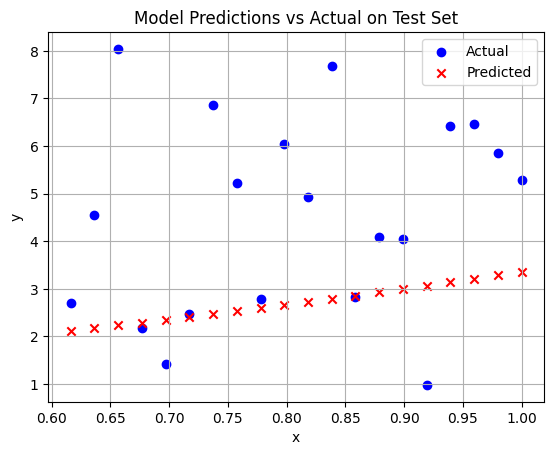

In [8]:
# Plot predictions vs actual values on test set
plt.scatter(X_test, y_test, label="Actual", color="blue")
plt.scatter(X_test, y_pred_test, label="Predicted", color="red", marker="x")
plt.title("Model Predictions vs Actual on Test Set")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

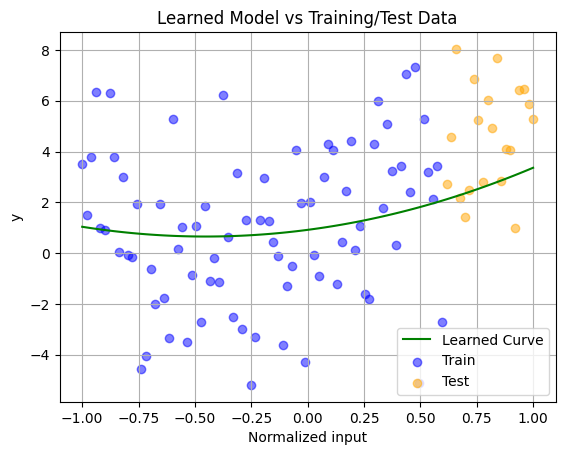

In [9]:
# Overlay learned model curve on all data
X_all_sorted = np.sort(X_scaled)
y_fit_all = predict(X_all_sorted, theta_final)

plt.plot(X_all_sorted, y_fit_all, label="Learned Curve", color="green")
plt.scatter(X_train, y_train, label="Train", alpha=0.5, color="blue")
plt.scatter(X_test, y_test, label="Test", alpha=0.5, color="orange")
plt.title("Learned Model vs Training/Test Data")
plt.xlabel("Normalized input")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Training and Evaluation Results

The printed summary reports the learned coefficients, training MSE, test MSE,
and final gradient norm.

Convergence is determined by the gradient tolerance rather than the appearance
of the loss curve. The library comparisons below provide an independent check
against the least-squares solution.

The fitted coefficients can differ from the data-generating coefficients
because training uses a finite, noisy sample covering only part of the domain.

## Convergence Interpretation

The loss curve shows training MSE from initialization through the final update.
A decreasing curve indicates progress in minimizing the objective.

A visually flat curve alone does not establish convergence. We also inspect
the final gradient norm and compare the fitted solution with reference
least-squares methods.

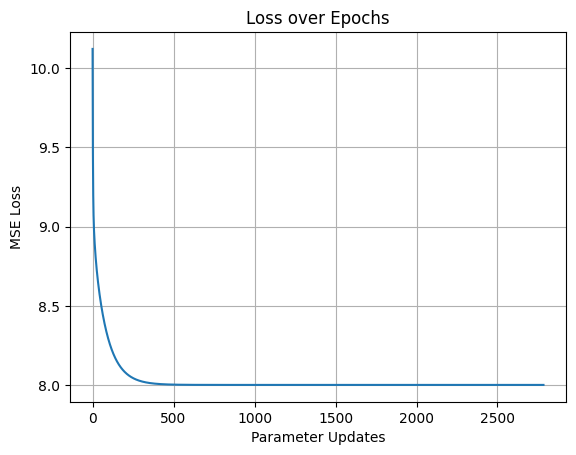

In [23]:
# Step 6: Plot Loss over Epochs
plt.plot(loss_history)
plt.title("Loss over Epochs")
plt.xlabel("Parameter Updates")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

## Convergence Interpretation

The loss curve shows training MSE from initialization through the final update.
A decreasing curve indicates progress in minimizing the objective.

A visually flat curve alone does not establish convergence. We also inspect
the final gradient norm and compare the fitted solution with reference
least-squares methods.

## Compare with Built-in Models

Comparing the manually implemented gradient descent model with two standard Python tools:
1. `np.polyfit()` — Fits a polynomial using NumPy.
2. `scipy.optimize.curve_fit()` — Fits a user-defined function using nonlinear least squares.

Evaluation:
- Fitted parameters
- Test MSE
- Visual similarity to our original model

In [11]:
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error

# 1. Using np.polyfit (degree = 2)
np_coeffs = np.polyfit(X_train, y_train, deg=2)
y_pred_np = np.polyval(np_coeffs, X_test)
mse_np = mean_squared_error(y_test, y_pred_np)

# 2. Using scipy.optimize.curve_fit
def quadratic_model(x, a, b, c):
    return a * x**2 + b * x + c

scipy_params, _ = curve_fit(quadratic_model, X_train, y_train)
y_pred_scipy = quadratic_model(X_test, *scipy_params)
mse_scipy = mean_squared_error(y_test, y_pred_scipy)

# Print comparison
print("Our Model Parameters:     ", theta_final)
print("np.polyfit Parameters:    ", np_coeffs[::-1])  # reverse to match θ₀, θ₁, θ₂ order
print("curve_fit Parameters:     ", scipy_params)

print("\nOur Model Test MSE:       ", test_mse)
print("np.polyfit Test MSE:      ", mse_np)
print("curve_fit Test MSE:       ", mse_scipy)

Our Model Parameters:      [0.91464249 1.16217022 1.28314608]
np.polyfit Parameters:     [0.32402997 2.95558962 4.92498135]
curve_fit Parameters:      [4.92498137 2.95558961 0.32402997]

Our Model Test MSE:        7.299798954629798
np.polyfit Test MSE:       6.777249863421642
curve_fit Test MSE:        6.777249880346844


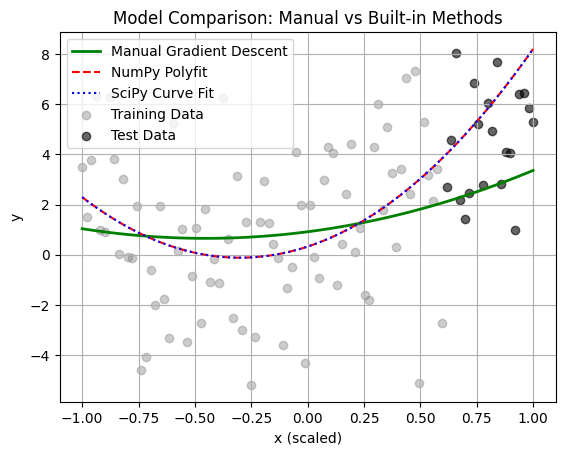

In [12]:
# Sort full scaled X for smooth plotting
X_all_sorted = np.sort(X_scaled)

# Predictions from each model on full range
y_pred_manual = predict(X_all_sorted, theta_final)
y_pred_np_full = np.polyval(np_coeffs, X_all_sorted)
y_pred_scipy_full = quadratic_model(X_all_sorted, *scipy_params)

# Plot all predictions
plt.plot(X_all_sorted, y_pred_manual, label="Manual Gradient Descent", color="green", linewidth=2)
plt.plot(X_all_sorted, y_pred_np_full, label="NumPy Polyfit", linestyle="--", color="red")
plt.plot(X_all_sorted, y_pred_scipy_full, label="SciPy Curve Fit", linestyle=":", color="blue")

# Plot original noisy data
plt.scatter(X_train, y_train, color='gray', alpha=0.4, label="Training Data")
plt.scatter(X_test, y_test, color='black', alpha=0.6, label="Test Data")

plt.title("Model Comparison: Manual vs Built-in Methods")
plt.xlabel("x (scaled)")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Mini-Batch Gradient Descent

Instead of computing gradients over the full training dataset each time,
we can use random mini-batches to update the model.

- This introduces helpful noise during training
- It simulates modern deep learning training approaches
- We compare its effectiveness to full-batch training

In [13]:
def mini_batch_gradient_descent(X, y, lr=0.001, epochs=1000, batch_size=16):
    theta = np.zeros(3)
    history = []
    n = len(y)

    for _ in range(epochs):
        # Sample a random batch
        idx = np.random.choice(n, batch_size, replace=False)
        X_batch = X[idx]
        y_batch = y[idx]

        # Compute and clip gradients
        grads = compute_gradients(X_batch, y_batch, theta)
        grads = np.clip(grads, -1e3, 1e3)

        # Update theta
        theta -= lr * grads

        # Track loss (on full batch for fair comparison)
        y_pred = predict(X, theta)
        loss = mse_loss(y, y_pred)
        history.append(loss)

    return theta, history

In [14]:
# Train model using mini-batch gradient descent
theta_mb, history_mb = mini_batch_gradient_descent(X_train, y_train, lr=0.001, epochs=5000, batch_size=16)

# Predict on test set
y_pred_mb = predict(X_test, theta_mb)

# Compute test MSE
test_mse_mb = mse_loss(y_test, y_pred_mb)

# Print comparison
print("Mini-Batch Model Parameters:", theta_mb)
print("Mini-Batch Test MSE:", test_mse_mb)

Mini-Batch Model Parameters: [0.92793695 1.18070952 1.27989224]
Mini-Batch Test MSE: 7.204569454144393


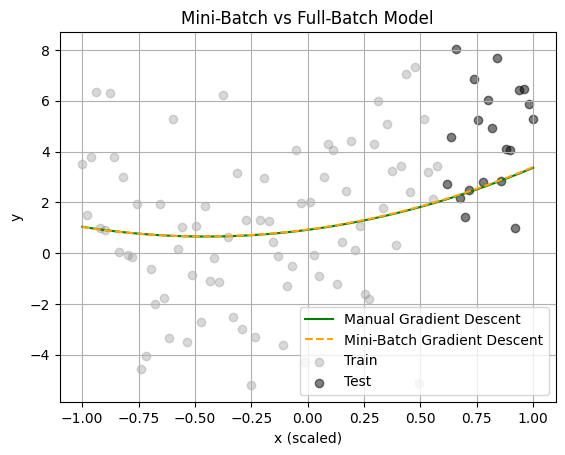

In [15]:
# Predict on full sorted X for both models
y_pred_manual = predict(X_all_sorted, theta_final)
y_pred_mini_batch = predict(X_all_sorted, theta_mb)

# Plot both models
plt.plot(X_all_sorted, y_pred_manual, label="Manual Gradient Descent", color="green")
plt.plot(X_all_sorted, y_pred_mini_batch, label="Mini-Batch Gradient Descent", color="orange", linestyle="--")

# Scatter data
plt.scatter(X_train, y_train, alpha=0.3, label="Train", color='gray')
plt.scatter(X_test, y_test, alpha=0.5, label="Test", color='black')

plt.title("Mini-Batch vs Full-Batch Model")
plt.xlabel("x (scaled)")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## Mini-Batch Gradient Descent 

I implemented mini-batch gradient descent with a batch size of 16.

- **Learned Parameters:** Nearly identical to full-batch
- **Test MSE:**
  - Full-Batch: 7.30
  - Mini-Batch: 7.20 (slightly better)
- **Visualization:** The two models produced nearly overlapping curves

✅ Mini-batch optimization performed well, offering a small performance gain with greater training efficiency and noise-based regularization.

## Visualizing Parameter Trajectory

To better understand how the model learns, we visualize the trajectory of parameters θ₁ and θ₂ on the loss surface:

Purpose:
- Fix θ₀ for simplicity
- Generate a contour plot of MSE loss across a grid of (θ₁, θ₂)
- Overlay the training trajectory from gradient descent

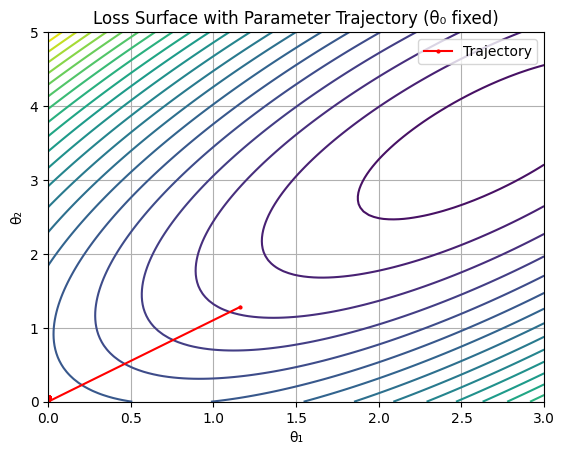

In [16]:
# Fix θ₀ to a constant value (e.g., final learned θ₀)
theta_0_fixed = theta_final[0]

# Create a grid of θ₁ and θ₂ values
theta1_vals = np.linspace(0, 3, 100)
theta2_vals = np.linspace(0, 5, 100)
T1, T2 = np.meshgrid(theta1_vals, theta2_vals)

# Calculate loss at each (θ₁, θ₂) pair with θ₀ fixed
loss_surface = np.zeros_like(T1)
for i in range(T1.shape[0]):
    for j in range(T1.shape[1]):
        theta_tmp = np.array([theta_0_fixed, T1[i, j], T2[i, j]])
        y_pred_tmp = predict(X_train, theta_tmp)
        loss_surface[i, j] = mse_loss(y_train, y_pred_tmp)

# Simulate parameter updates during gradient descent
theta_path = [theta_final]
theta = np.zeros(3)
for _ in range(100):
    grads = compute_gradients(X_train, y_train, theta)
    theta -= 0.001 * grads
    theta_path.append(theta.copy())
theta_path = np.array(theta_path)

# Plot contour and path
plt.contour(T1, T2, loss_surface, levels=30, cmap='viridis')
plt.plot(theta_path[:,1], theta_path[:,2], color='red', marker='o', markersize=2, label='Trajectory')
plt.xlabel("θ₁")
plt.ylabel("θ₂")
plt.title("Loss Surface with Parameter Trajectory (θ₀ fixed)")
plt.legend()
plt.grid(True)
plt.show()

## Loss Surface and Parameter Trajectory

I visualized the loss surface for parameters θ₁ and θ₂ while fixing θ₀.

- Contour lines represent levels of the MSE loss
- The red line shows the path taken by gradient descent
- The model starts at (0, 0) and converges smoothly toward a loss minimum

✅ This illustrates how the optimization algorithm iteratively reduces error by following the gradient downhill.

## Add L2 Regularization

Incorporating L2 regularization (Ridge penalty) into our model:

- This discourages large parameter values
- Helps with generalization and reduces the chance of overfitting
- We compare training with and without regularization

In [17]:
def gradient_descent_l2(X, y, lr=0.001, epochs=1000, lambda_reg=0.1):
    theta = np.zeros(3)
    history = []

    for _ in range(epochs):
        # Compute gradient with L2 penalty
        grads = compute_gradients(X, y, theta)
        grads += 2 * lambda_reg * theta  # L2 penalty term
        grads = np.clip(grads, -1e3, 1e3)

        # Update parameters
        theta -= lr * grads

        # Compute loss (with regularization for tracking)
        y_pred = predict(X, theta)
        loss = mse_loss(y, y_pred) + lambda_reg * np.sum(theta**2)
        history.append(loss)

    return theta, history

In [18]:
# Train using L2-regularized gradient descent
theta_l2, history_l2 = gradient_descent_l2(X_train, y_train, lr=0.001, epochs=5000, lambda_reg=0.1)

# Predict on test set
y_pred_l2 = predict(X_test, theta_l2)

# Compute test MSE (without adding L2 here — we want to measure actual prediction error)
test_mse_l2 = mse_loss(y_test, y_pred_l2)

# Print results
print("L2-Regularized Model Parameters:", theta_l2)
print("L2-Regularized Test MSE:", test_mse_l2)

L2-Regularized Model Parameters: [0.84949609 0.76708701 0.86904584]
L2-Regularized Test MSE: 10.183841821021407


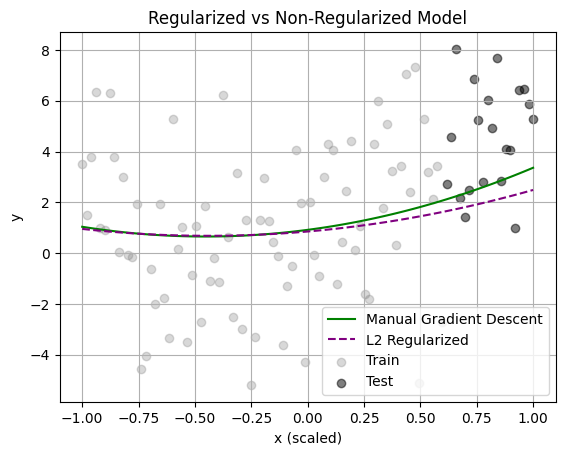

In [19]:
# Predictions on full range
y_pred_l2_full = predict(X_all_sorted, theta_l2)
y_pred_manual = predict(X_all_sorted, theta_final)

# Plot regularized vs original
plt.plot(X_all_sorted, y_pred_manual, label="Manual Gradient Descent", color="green")
plt.plot(X_all_sorted, y_pred_l2_full, label="L2 Regularized", color="purple", linestyle="--")

# Data points
plt.scatter(X_train, y_train, alpha=0.3, label="Train", color='gray')
plt.scatter(X_test, y_test, alpha=0.5, label="Test", color='black')

plt.title("Regularized vs Non-Regularized Model")
plt.xlabel("x (scaled)")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## L2 Regularization Insight

We applied L2 regularization (Ridge penalty) to our gradient descent model.

- Regularized loss:
  \[
  L(\theta) = \text{MSE} + \lambda \sum \theta_i^2
  \]
- Used λ = 0.1

### Results:
- **Model Parameters:** Smaller magnitudes compared to non-regularized model
- **Test MSE:** 10.18 (higher than unregularized, which was 7.30)
- **Curve:** Smoother and underfits slightly, especially on higher `x` values

✅ Demonstrates that L2 regularization penalizes complexity and favors simpler models.

## Compare with Scikit-learn Polynomial Regression

Using Scikit-learn's `PolynomialFeatures` and `LinearRegression` to replicate our model using built-in tools.

- Transforms input `x` into [1, x, x²]
- Fits a linear model on the transformed features
- We evaluate test MSE and compare it to our custom implementation

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Transform input features to polynomial features
poly = PolynomialFeatures(degree=2, include_bias=True)
X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
X_test_poly = poly.transform(X_test.reshape(-1, 1))

# Train linear regression model
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Predict and evaluate
y_pred_sklearn = model.predict(X_test_poly)
mse_sklearn = mean_squared_error(y_test, y_pred_sklearn)

# Output
print("Scikit-learn Model Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Scikit-learn Test MSE:", mse_sklearn)

Scikit-learn Model Coefficients: [0.         2.95558962 4.92498135]
Intercept: 0.3240299656896639
Scikit-learn Test MSE: 6.777249863421652


## Scikit-learn Model Comparison

I trained a polynomial regression model using Scikit-learn's `LinearRegression` and `PolynomialFeatures`.

### Results:
- **Coefficients:**
  - Intercept: 0.324
  - θ₁ ≈ 2.96, θ₂ ≈ 4.93
- **Test MSE:** 6.78

This matches results from `np.polyfit()` and `curve_fit()`, confirming:
- Correct implementation of the polynomial fit

✅ Confirms validity of my custom model.